# 08 · Exploración de los datos de clima (ERA5, NASA POWER y estaciones de ANACAFE)

Notebook de **análisis**: no entrena nada. Responde: ¿cómo es el clima de cada región?, ¿ERA5 se parece a lo que miden las estaciones? y ¿hay
tendencia de largo plazo? Las cifras salen de `data/raw/openmeteo/` y `data/raw/anacafe/`.

In [1]:
import sys
from pathlib import Path
ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
from src.forecast.anacafe import load_clean
from src.forecast.data import load_region
from src.forecast.download import load_regions
REG = load_regions()
ERA = {r: load_region(r) for r in REG}
SPEC = pd.DataFrame(REG).T[["estacion_anacafe", "lat", "lon", "elevation_m"]]
display(SPEC)

,estacion_anacafe,lat,lon,elevation_m
huehuetenango,15.0,15.62838,-91.95908,966.0
antigua,3.0,14.52932,-90.74739,1521.0
coban,163.0,15.46096,-90.37600,1332.0
atitlan,71.0,14.65905,-91.43093,1197.0
fraijanes,8.0,14.48467,-90.44667,1713.0
nuevo_oriente,130.0,14.62282,-89.37523,1399.0


In [2]:
rows = []
for r, df in ERA.items():
    rows.append({"región": r, "desde": df.index[0].date(), "hasta": df.index[-1].date(), "días": len(df),
                 "T media °C": df["temperature_2m_mean"].mean(), "HR media %": df["relative_humidity_2m_mean"].mean(),
                 "lluvia anual mm": df["precipitation_sum"].resample("YE").sum().iloc[:-1].mean()})
display(pd.DataFrame(rows).set_index("región").round(1))

,desde,hasta,días,T media °C,HR media %,lluvia anual mm
región,,,,,,
huehuetenango,1980-01-01,2026-10-23,17098,21.1,70.7,1088.3
antigua,1980-01-01,2026-10-23,17098,19.3,77.6,1642.4
coban,1980-01-01,2026-10-23,17098,18.5,88.2,3390.3
atitlan,1980-01-01,2026-10-23,17098,20.2,81.0,3083.4
fraijanes,1980-01-01,2026-10-23,17098,17.3,78.2,1648.2
nuevo_oriente,1980-01-01,2026-10-23,17098,18.8,81.5,1532.5


## 1. Ciclo anual por región
La temporada de lluvias (mayo a octubre) y la humedad alta son las condiciones que favorecen a la roya.

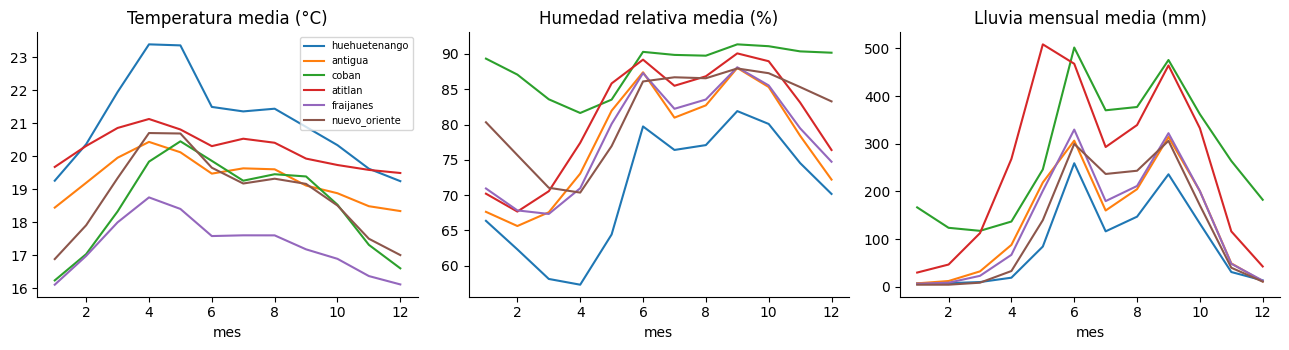

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for r, df in ERA.items():
    ax[0].plot(range(1, 13), df["temperature_2m_mean"].groupby(df.index.month).mean(), label=r)
    ax[1].plot(range(1, 13), df["relative_humidity_2m_mean"].groupby(df.index.month).mean(), label=r)
    ax[2].plot(range(1, 13), df["precipitation_sum"].groupby(df.index.month).mean() * 30, label=r)
for a, t in zip(ax, ["Temperatura media (°C)", "Humedad relativa media (%)", "Lluvia mensual media (mm)"]):
    a.set_title(t); a.set_xlabel("mes")
ax[0].legend(fontsize=7); plt.tight_layout(); plt.show()

## 2. La lluvia diaria está muy sesgada (por eso se usa log1p)

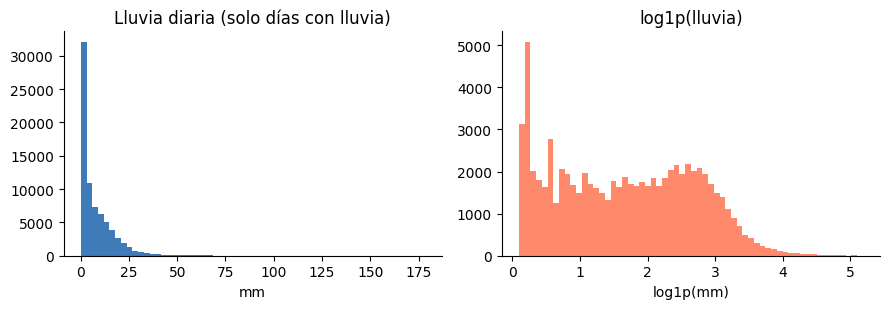

Días sin lluvia: 28% · máximo diario: 178 mm · asimetría: 3.8 (log1p: 0.5)


In [4]:
rain = pd.concat([df["precipitation_sum"] for df in ERA.values()])
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
ax[0].hist(rain[rain > 0], bins=60, color="#3F7BB8"); ax[0].set_title("Lluvia diaria (solo días con lluvia)"); ax[0].set_xlabel("mm")
ax[1].hist(np.log1p(rain[rain > 0]), bins=60, color="#FF8A6B"); ax[1].set_title("log1p(lluvia)"); ax[1].set_xlabel("log1p(mm)")
plt.tight_layout(); plt.show()
print(f"Días sin lluvia: {(rain == 0).mean():.0%} · máximo diario: {rain.max():.0f} mm · asimetría: {rain.skew():.1f} (log1p: {np.log1p(rain).skew():.1f})")

## 3. Tendencia de largo plazo
Pendiente de la temperatura media anual (1981–2025, años completos) por región. Sirve para entender por qué el pronóstico entrenado con décadas pasadas puede estar sesgado hoy.

,°C por década,T media 1981–2000,T media 2011–2025
región,,,
huehuetenango,0.19,20.85,21.36
antigua,0.23,19.03,19.67
coban,0.15,18.39,18.81
atitlan,0.30,19.88,20.70
fraijanes,0.18,17.10,17.60
nuevo_oriente,0.18,18.64,19.16


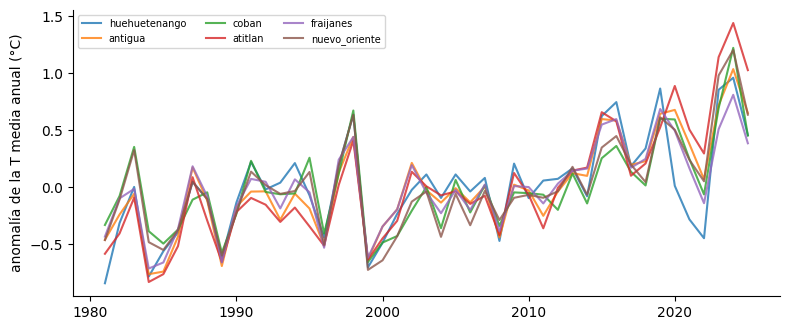

In [5]:
rows = []
for r, df in ERA.items():
    ann = df["temperature_2m_mean"].resample("YE").mean()
    ann = ann[(ann.index.year >= 1981) & (ann.index.year <= 2025)]
    slope, intercept = np.polyfit(ann.index.year, ann.values, 1)
    rows.append({"región": r, "°C por década": slope * 10, "T media 1981–2000": ann[ann.index.year <= 2000].mean(), "T media 2011–2025": ann[ann.index.year >= 2011].mean()})
trend = pd.DataFrame(rows).set_index("región")
display(trend.round(2))
fig, ax = plt.subplots(figsize=(8, 3.4))
for r, df in ERA.items():
    ann = df["temperature_2m_mean"].resample("YE").mean(); ann = ann[(ann.index.year >= 1981) & (ann.index.year <= 2025)]
    ax.plot(ann.index.year, ann.values - ann.mean(), label=r, alpha=0.8)
ax.set_ylabel("anomalía de la T media anual (°C)"); ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

## 4. ERA5 frente a las estaciones de ANACAFE
Sesgo medio mensual (estación − ERA5) en los días en que ambos tienen dato, tras el control de calidad.

In [6]:
stations, report = load_clean()
display(report.head(12))

,estacion,nombre,inicio,fin,dias_con_fila,dias_calendario,huecos,qc_viento_en_cero,qc_lluvia_cero_en_temporada_de_lluvias,qc_humedad_fuera_de_rango,qc_lluvia_imposible,qc_temperatura_fuera_de_rango,qc_temperatura_incoherente,t_mean_validos_pct,lluvia_validos_pct,viento_validos_pct,qc_valor_congelado
0,3,Bella Vista,2020-01-01,2026-10-30,2451,2495,44,122.0,137.0,0,0,61,0,97.7,92.7,93.3,0.0
1,8,La Mandarina,2020-03-13,2026-09-30,2015,2393,378,305.0,0.0,0,0,184,0,81.0,84.2,71.5,38.0
2,15,Rancho Carmela,2020-01-01,2026-10-30,2301,2495,194,210.0,0.0,0,0,16,0,91.0,92.2,83.8,93.0
3,71,Cooperativa Nahuala,2020-01-01,2026-09-25,2127,2460,333,636.0,135.0,0,0,1,0,86.5,81.0,60.6,0.0
4,130,Chiramay,2020-03-01,2026-10-30,2327,2435,108,346.0,0.0,0,0,0,0,95.6,95.6,81.4,0.0
5,163,Oficina Regional VI,2021-12-16,2026-10-30,1735,1780,45,0.0,0.0,0,0,0,0,97.5,97.5,97.5,0.0


In [7]:
rows = []
for r, spec in REG.items():
    st = stations[stations["station_id"] == spec["estacion_anacafe"]].set_index("date")
    j = ERA[r].join(st, how="inner")
    for era_col, st_col, name in [("temperature_2m_mean", "t_mean", "temperatura"), ("relative_humidity_2m_mean", "rh_mean", "humedad"), ("precipitation_sum", "rain_mm", "lluvia")]:
        ok = j[[era_col, st_col]].dropna()
        rows.append({"región": r, "variable": name, "días": len(ok), "sesgo (estación − ERA5)": (ok[st_col] - ok[era_col]).mean(),
                     "MAE": (ok[st_col] - ok[era_col]).abs().mean(), "correlación": ok[era_col].corr(ok[st_col])})
cmp = pd.DataFrame(rows)
display(cmp.pivot(index="región", columns="variable", values=["sesgo (estación − ERA5)", "correlación"]).round(2))

sesgo (estación − ERA5)                    correlación                   
variable                      humedad lluvia temperatura     humedad lluvia temperatura
región                                                                                 
antigua                          0.34  -2.33       -1.20        0.70   0.43        0.63
atitlan                          5.77   0.30       -1.83        0.80   0.35        0.65
coban                            1.64  -1.95       -1.03        0.71   0.56        0.90
fraijanes                       -2.96  -1.67        0.42        0.29   0.43        0.56
huehuetenango                    8.20   3.36        0.65        0.77   0.37        0.71
nuevo_oriente                    6.40   0.13       -0.33        0.67   0.50        0.80

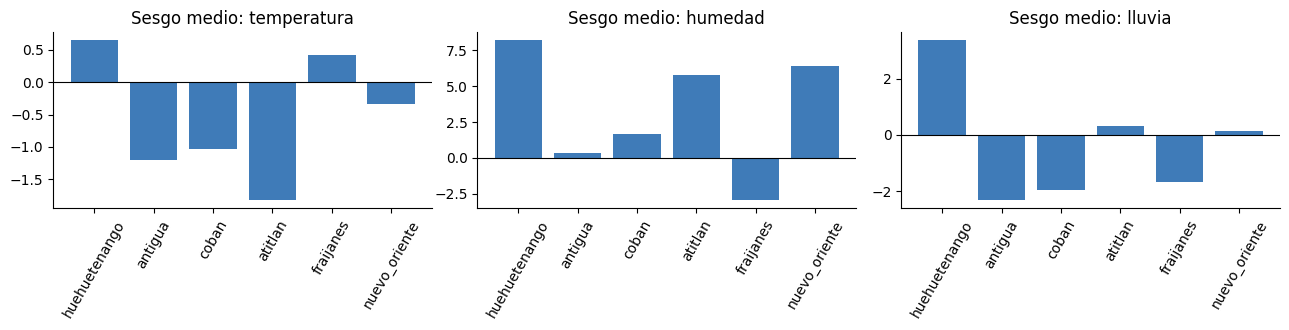

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))
for a, name in zip(ax, ["temperatura", "humedad", "lluvia"]):
    s = cmp[cmp["variable"] == name]
    a.bar(s["región"], s["sesgo (estación − ERA5)"], color="#3F7BB8"); a.axhline(0, color="k", lw=0.8); a.set_title(f"Sesgo medio: {name}"); a.tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

## 5. Conclusiones para el pronóstico
- Cada región tiene un ciclo anual propio; por eso la evidencia climática se mide **respecto de lo habitual en la finca y la época** (Fase 4) y no con cortes absolutos.
- La lluvia es muy sesgada: se usa `log1p` al entrenar y al convertir el pronóstico en evidencia.
- El sesgo de ERA5 frente a las estaciones cambia de signo y de tamaño según la región (ver las tablas), y la correlación diaria de la lluvia es baja en todas: por eso se afina con las estaciones y se evalúa contra ellas, no contra ERA5.
- La tendencia de temperatura es positiva en las regiones; el pronóstico entrenado hasta 2017 puede subestimar el clima actual (ver `docs/resultados_forecast.md`).